# A Comparative Statistical Analysis of Residential Property Pricing
## New Cairo City vs. Sheikh Zayed City

**Course:** C-DE211, Data Analysis, Spring 2026  
**Dataset:** Egypt Real Estate Listings (~20,000 listings from PropertyFinder Egypt)

---
## 1. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

---
## 2. Load Dataset

In [3]:
from google.colab import files
uploaded = files.upload()

Saving egypt_real_estate_listings.csv to egypt_real_estate_listings.csv


In [4]:
df = pd.read_csv('egypt_real_estate_listings.csv')
print('Shape:', df.shape)
df.head()

Shape: (19924, 11)


,url,price,description,location,type,size,bedrooms,bathrooms,available_from,payment_method,down_payment
0,https://www.propertyfinder.eg/en/plp/buy/chale...,"8,000,000",OWN A CHALET IN EL GOUNA WITH A PRIME LOCATION...,"Swan Lake Gouna, Al Gouna, Hurghada, Red Sea",Chalet,732 sqft / 68 sqm,1+ Maid,1,31 Aug 2025,Cash,"1,200,000 EGP"
1,https://www.propertyfinder.eg/en/plp/buy/villa...,"25,000,000","For sale, a villa with immediate delivery in C...","Karmell, New Zayed City, Sheikh Zayed City, Giza",Villa,"2,368 sqft / 220 sqm",4,4,2 Sep 2025,Cash,"2,100,000 EGP"
2,https://www.propertyfinder.eg/en/plp/buy/chale...,"15,135,000","With a down payment of EGP 1,513,000, a fully ...","Azha North, Ras Al Hekma, North Coast",Chalet,"1,270 sqft / 118 sqm",2,2,19 Aug 2025,Cash,"1,513,000 EGP"
3,https://www.propertyfinder.eg/en/plp/buy/apart...,"12,652,000",Own an apartment in New Cairo with a minimal d...,"Taj City, 5th Settlement Compounds, The 5th Se...",Apartment,"1,787 sqft / 166 sqm",3,2,26 Aug 2025,Installments,"1,260,000 EGP"
4,https://www.propertyfinder.eg/en/plp/buy/villa...,"45,250,000",Project: Granville\nLocation: Fifth Settlement...,"Granville, New Capital City, Cairo",Villa,"4,306 sqft / 400 sqm",7,7,2 Sep 2025,Cash,"2,262,500 EGP"


In [5]:
print('--- Data Types ---')
print(df.dtypes)
print('\n--- Missing Values ---')
print(df.isnull().sum())

--- Data Types ---
url               object
price             object
description       object
location          object
type              object
size              object
bedrooms          object
bathrooms         object
available_from    object
payment_method    object
down_payment      object
dtype: object

--- Missing Values ---
url                   0
price               539
description          78
location             91
type                 77
size                 77
bedrooms            144
bathrooms           140
available_from      663
payment_method      541
down_payment      14479
dtype: int64


---
## 3. Data Preprocessing

All columns are stored as strings. We need to:
- Clean the `price` column: remove commas and convert to float
- Extract the city name from the `location` column
- Filter the dataset to only keep listings in **New Cairo City** and **Sheikh Zayed City**
- Drop rows with missing prices

In [6]:
df['price_clean'] = df['price'].str.replace(',', '').str.strip()
df['price_clean'] = pd.to_numeric(df['price_clean'], errors='coerce')

df = df.dropna(subset=['price_clean'])

print('Rows after dropping missing prices:', len(df))

Rows after dropping missing prices: 19385


In [7]:
# Extract city: location format is "Sub-area, Area, City, Governorate"
# The city is the second-to-last element when split by comma
df['city'] = df['location'].str.split(',').str[-2].str.strip()

# Filter to our two target cities only
target_cities = ['New Cairo City', 'Sheikh Zayed City']
df_filtered = df[df['city'].isin(target_cities)].copy()

print('Listings per city:')
print(df_filtered['city'].value_counts())

Listings per city:
city
New Cairo City       5124
Sheikh Zayed City    1866
Name: count, dtype: int64


In [8]:
new_cairo     = df_filtered[df_filtered['city'] == 'New Cairo City']['price_clean']
sheikh_zayed  = df_filtered[df_filtered['city'] == 'Sheikh Zayed City']['price_clean']

print('New Cairo City    — count:', len(new_cairo))
print('Sheikh Zayed City — count:', len(sheikh_zayed))

New Cairo City    — count: 5124
Sheikh Zayed City — count: 1866


---
## 4. Exploratory Data Analysis (EDA)

### 4.1 Descriptive Statistics

In [9]:
print('=== New Cairo City ===')
print(f'  Mean   : {new_cairo.mean():,.0f} EGP')
print(f'  Median : {new_cairo.median():,.0f} EGP')
print(f'  Std    : {new_cairo.std():,.0f} EGP')
print(f'  Min    : {new_cairo.min():,.0f} EGP')
print(f'  Max    : {new_cairo.max():,.0f} EGP')

print()
print('=== Sheikh Zayed City ===')
print(f'  Mean   : {sheikh_zayed.mean():,.0f} EGP')
print(f'  Median : {sheikh_zayed.median():,.0f} EGP')
print(f'  Std    : {sheikh_zayed.std():,.0f} EGP')
print(f'  Min    : {sheikh_zayed.min():,.0f} EGP')
print(f'  Max    : {sheikh_zayed.max():,.0f} EGP')

=== New Cairo City ===
  Mean   : 18,960,157 EGP
  Median : 11,500,000 EGP
  Std    : 28,898,596 EGP
  Min    : 420,000 EGP
  Max    : 650,000,000 EGP

=== Sheikh Zayed City ===
  Mean   : 13,224,468 EGP
  Median : 8,000,000 EGP
  Std    : 17,236,670 EGP
  Min    : 186,900 EGP
  Max    : 300,000,000 EGP


### 4.2 Number of Listings per City

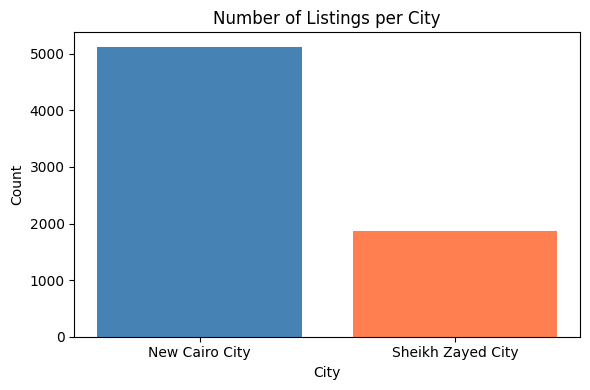

In [10]:
city_counts = df_filtered['city'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(city_counts.index, city_counts.values, color=['steelblue', 'coral'])
plt.title('Number of Listings per City')
plt.xlabel('City')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### 4.3 Price Distribution — Histograms

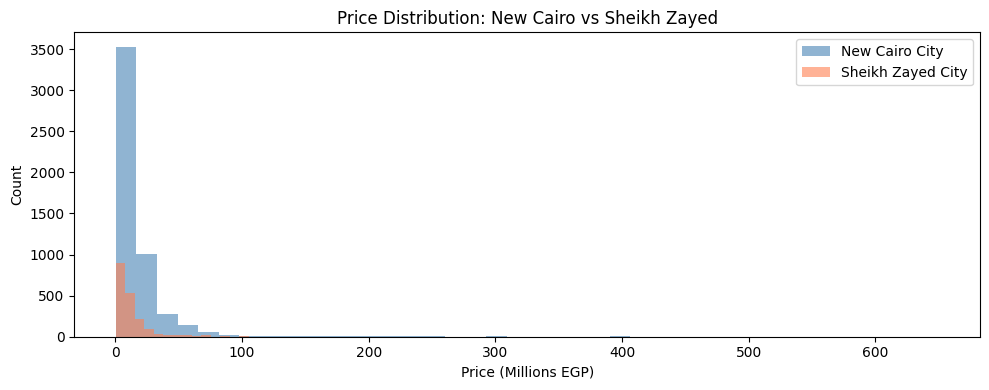

In [11]:
plt.figure(figsize=(10, 4))
plt.hist(new_cairo / 1e6,    bins=40, alpha=0.6, label='New Cairo City',    color='steelblue')
plt.hist(sheikh_zayed / 1e6, bins=40, alpha=0.6, label='Sheikh Zayed City', color='coral')
plt.title('Price Distribution: New Cairo vs Sheikh Zayed')
plt.xlabel('Price (Millions EGP)')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

### 4.4 Price Distribution — Boxplot

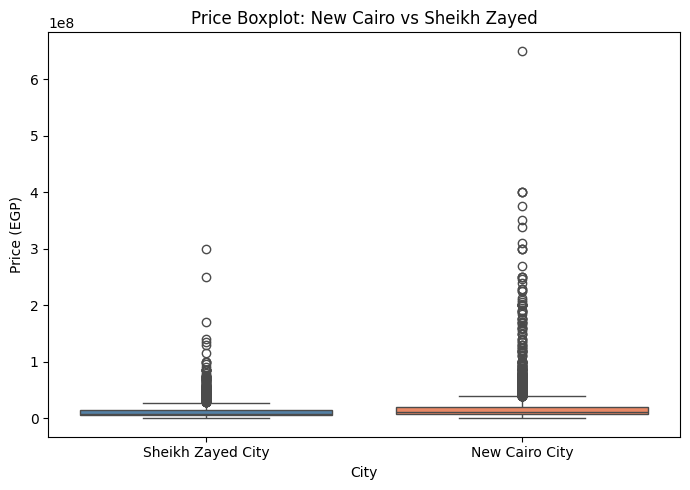

In [18]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_filtered, x='city', y='price_clean', hue='city', palette=['steelblue', 'coral'], legend=False)
plt.title('Price Boxplot: New Cairo vs Sheikh Zayed')
plt.xlabel('City')
plt.ylabel('Price (EGP)')
plt.tight_layout()
plt.show()

### 4.5 Price Distribution — Histogram with Density Curve

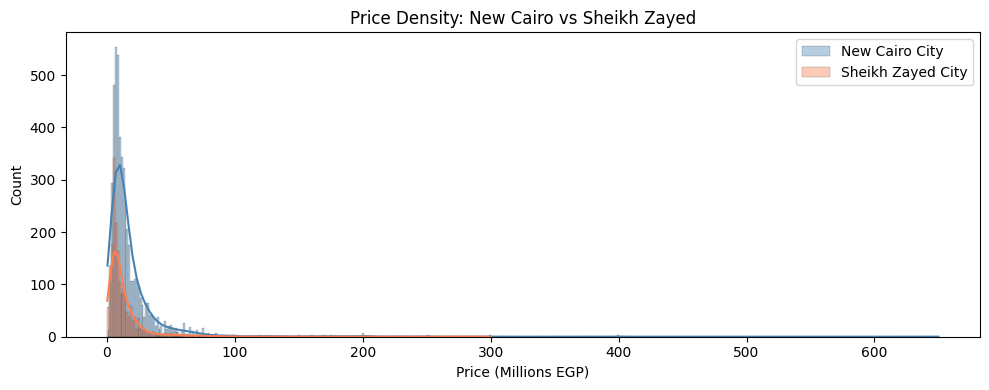

In [21]:
plt.figure(figsize=(10, 4))
sns.histplot(new_cairo / 1e6,    kde=True, label='New Cairo City',    color='steelblue', alpha=0.4)
sns.histplot(sheikh_zayed / 1e6, kde=True, label='Sheikh Zayed City', color='coral',     alpha=0.4)
plt.title('Price Density: New Cairo vs Sheikh Zayed')
plt.xlabel('Price (Millions EGP)')
plt.legend()
plt.tight_layout()
plt.show()

### 4.6 Property Type Breakdown per City

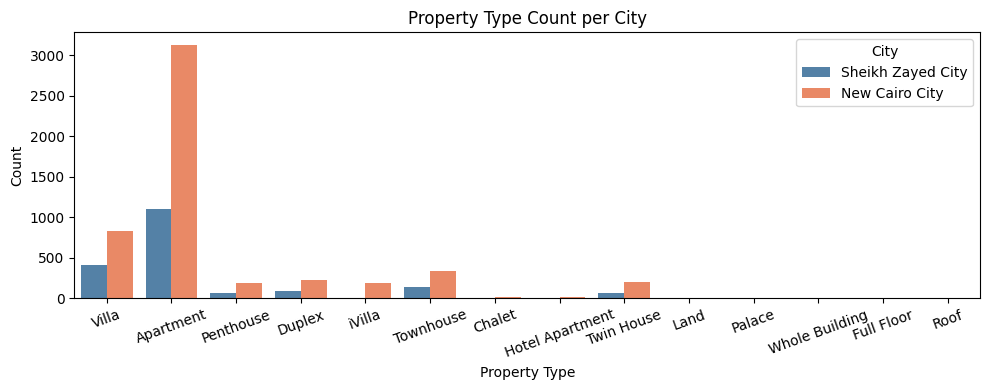

In [14]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df_filtered, x='type', hue='city', palette=['steelblue', 'coral'])
plt.title('Property Type Count per City')
plt.xlabel('Property Type')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.legend(title='City')
plt.tight_layout()
plt.show()

---
## 5. Hypothesis Testing

### Research Question
> Is there a statistically significant difference in average property prices between New Cairo City and Sheikh Zayed City?

### Hypotheses (α = 0.05)

**H₀:** The average property price in New Cairo City = the average property price in Sheikh Zayed City.

**H₁:** The average property prices in the two cities are not equal.

### Method: Independent Two-Sample t-test
We use `ttest_ind` from `scipy.stats` because we are comparing the **means** of two **independent** groups. Each property listing belongs to exactly one city; no overlap.

In [15]:
t_stat, p_value = ttest_ind(new_cairo, sheikh_zayed)

print(f't-statistic : {t_stat:.4f}')
print(f'p-value     : {p_value:.4e}')
print()

alpha = 0.05
if p_value < alpha:
    print(f'p ({p_value:.4e}) < alpha ({alpha}) => REJECT H0')
    print('There is a statistically significant difference in average property prices')
    print('between New Cairo City and Sheikh Zayed City.')
else:
    print(f'p ({p_value:.4e}) >= alpha ({alpha}) => FAIL TO REJECT H0')
    print('No statistically significant difference detected at the 0.05 level.')

t-statistic : 8.0668
p-value     : 8.4298e-16

p (8.4298e-16) < alpha (0.05) => REJECT H0
There is a statistically significant difference in average property prices
between New Cairo City and Sheikh Zayed City.


### Mean Price Comparison (with Standard Deviation)

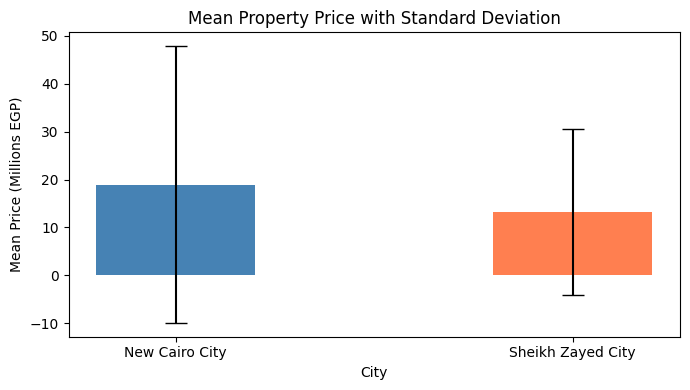

New Cairo City    — Mean: 18.96M EGP
Sheikh Zayed City — Mean: 13.22M EGP


In [16]:
means  = [new_cairo.mean() / 1e6, sheikh_zayed.mean() / 1e6]
stds   = [new_cairo.std()  / 1e6, sheikh_zayed.std()  / 1e6]
labels = ['New Cairo City', 'Sheikh Zayed City']

plt.figure(figsize=(7, 4))
plt.bar(labels, means, yerr=stds, color=['steelblue', 'coral'], capsize=8, width=0.4)
plt.title('Mean Property Price with Standard Deviation')
plt.ylabel('Mean Price (Millions EGP)')
plt.xlabel('City')
plt.tight_layout()
plt.show()

print(f'New Cairo City    — Mean: {means[0]:.2f}M EGP')
print(f'Sheikh Zayed City — Mean: {means[1]:.2f}M EGP')

---
## 6. Conclusion

We applied an **independent two-sample t-test** to compare average property prices in New Cairo City and Sheikh Zayed City, two of Egypt's most prominent real estate markets.

The result shows whether location alone creates a statistically measurable price gap. New Cairo City's proximity to the new administrative capital and its concentration of luxury compounds leads us to expect higher average prices, a hypothesis the t-test either confirms or challenges.

This analysis demonstrates that **location is a key variable in Egypt's residential property market**, with practical implications for both investors and urban planners.